
# SolarOps — Baseline Solar Power Prediction

## Objective

Build our first machine learning baseline to predict solar AC power output using PVDAQ System 2107.

### Features (X)
- Plane-of-array irradiance
- Ambient temperature
- Wind speed

### Target (y)
- Revenue-grade AC output meter measurement

### Models
1. Dummy Regressor — reference benchmark
2. Linear Regression — first ML model

### Evaluation
- MAE
- RMSE
- R²

### Engineering principles
- Preserve original source data.
- Use Universal Data Cleaner for data-quality inspection.
- Avoid data leakage.
- Preserve chronological order.
- Compare every model against a simple benchmark.


In [30]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload



## 1. Imports and project configuration

Import the libraries required for data ingestion, exploration, feature preparation, and baseline modelling.


In [31]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from data_cleaner import CleanerConfig, DataCleaner

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

RANDOM_STATE = 42

print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("SolarOps baseline environment ready.")

pandas: 3.1.1
NumPy: 2.5.4
SolarOps baseline environment ready.



## 2. Locate the PVDAQ datasets

We use the four locally downloaded source CSV files.

The first baseline will use:
- Irradiance
- Environmental measurements
- Revenue-grade meter output

The electrical dataset contains inverter-level signals. We will retain it for later investigation rather than loading hundreds of megabytes unnecessarily into our first baseline.


In [32]:

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "pyproject.toml").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("SolarOps project root not found.")
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = (
    PROJECT_ROOT
    / "data/raw/pvdaq/2023-solar-data-prize/system-2107"
)

SOURCE_FILES = {
    "electrical": DATA_DIR / "2107_electrical_data.csv",
    "environment": DATA_DIR / "2107_environment_data.csv",
    "irradiance": DATA_DIR / "2107_irradiance_data.csv",
    "meter": DATA_DIR / "2107_meter_15m_data.csv",
}

for name, path in SOURCE_FILES.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {name} dataset: {path}")
    print(f"{name:12} | {path.stat().st_size / 1024**2:,.2f} MB")


electrical   | 418.25 MB
environment  | 7.34 MB
irradiance   | 13.34 MB
meter        | 6.03 MB



## 3. Load the modelling datasets

We load the environment, irradiance, and meter datasets.

We parse `measured_on` as a datetime column so we can perform chronological analysis and timestamp alignment.

We intentionally do not load the electrical dataset yet.


In [33]:
from solarops.pipeline import load_raw

raw = load_raw(PROJECT_ROOT/DATA_DIR)   # ← uses the DATA_DIR cell 3 already made

for k, v in raw.items():
    print(f"{k:12} | rows={len(v):>7,} | measured_on dtype={v['measured_on'].dtype}")

meter        | rows=240,062 | measured_on dtype=datetime64[us]
environment  | rows=206,008 | measured_on dtype=datetime64[us]
irradiance   | rows=531,019 | measured_on dtype=datetime64[us]


In [34]:
# ! Delete Me

# environment_raw = pd.read_csv(
#     SOURCE_FILES["environment"],
#     parse_dates=["measured_on"],
# )

# irradiance_raw = pd.read_csv(
#     SOURCE_FILES["irradiance"],
#     parse_dates=["measured_on"],
# )

# meter_raw = pd.read_csv(
#     SOURCE_FILES["meter"],
#     parse_dates=["measured_on"],
# )

# print("All three modelling datasets loaded.")


In [35]:

raw_datasets = {
    "environment": raw['environment'],
    "irradiance": raw['irradiance'],
    "meter": raw['meter'],
}

for name, df in raw_datasets.items():
    print(f"\n{'=' * 55}")
    print(name.upper())
    print("Shape:", df.shape)
    print("Date range:", df["measured_on"].min(), "to", df["measured_on"].max())
    print("Duplicate timestamps:", df["measured_on"].duplicated().sum())
    print("Missing values:", df.isna().sum().sum())
    display(df.head(3))



ENVIRONMENT
Shape: (206008, 4)
Date range: 2017-12-01 00:00:00 to 2023-10-31 23:45:00
Duplicate timestamps: 0
Missing values: 156


,measured_on,ambient_temperature_o_149575,wind_speed_o_149576,wind_direction_o_149577
0,2017-12-01 00:00:00,38.800,1.200,156.000
1,2017-12-01 00:15:00,38.800,1.200,156.000
2,2017-12-01 00:30:00,38.800,1.200,156.000



IRRADIANCE
Shape: (531019, 2)
Date range: 2017-11-01 07:10:00 to 2023-11-01 23:55:00
Duplicate timestamps: 0
Missing values: 0


,measured_on,poa_irradiance_o_149574
0,2017-11-01 07:10:00,0.000
1,2017-11-01 07:15:00,0.000
2,2017-11-01 07:20:00,0.000



METER
Shape: (240062, 2)
Date range: 2017-01-01 00:15:00 to 2023-11-09 23:30:00
Duplicate timestamps: 0
Missing values: 0


,measured_on,meter_revenue_grade_ac_output_meter_149578
0,2017-01-01 00:15:00,0.000
1,2017-01-01 00:30:00,0.000
2,2017-01-01 00:45:00,0.000



## 4. Define the baseline features and target

We explicitly select the columns relevant to our first prediction problem.

Features:

- POA irradiance
- Ambient temperature
- Wind speed

Target:

- Revenue-grade AC output meter measurement

We exclude wind direction from this first baseline. We can investigate whether it adds predictive value in a later experiment.

We also avoid using inverter electrical readings as inputs because they may contain signals closely related to the output we are trying to predict. We will investigate that possibility later.


In [36]:
# ! Delete Me
# IRRADIANCE_COL = "poa_irradiance_o_149574"
# TEMPERATURE_COL = "ambient_temperature_o_149575"
# WIND_SPEED_COL = "wind_speed_o_149576"
# TARGET_COL = "meter_revenue_grade_ac_output_meter_149578"

# FEATURES = [
#     IRRADIANCE_COL,
#     TEMPERATURE_COL,
#     WIND_SPEED_COL,
# ]

# required_columns = {
#     "environment": [TEMPERATURE_COL, WIND_SPEED_COL],
#     "irradiance": [IRRADIANCE_COL],
#     "meter": [TARGET_COL],
# }

# for name, columns in required_columns.items():
#     missing = set(columns) - set(raw_datasets[name].columns)
#     if missing:
#         raise ValueError(f"{name} is missing expected columns: {missing}")

# print("All expected modelling columns are available.")


## 5. Align to a common 15-min grid

Meter + environment are ~15 min. Irradiance is ~5 min.
Plan: filter to common date window → resample irradiance to 15 min (mean, right-closed) → merge on timestamp with `validate="one_to_one"`.

Assumptions (to verify against PVDAQ docs):
- meter timestamp = end of its interval
- no interpolation
- resampling gaps are honest, not filled

In [42]:
from solarops.pipeline import align_15m

df = align_15m(raw)
print("shape:", df.shape)
print("window:", df["measured_on"].min(), "→", df["measured_on"].max())
print("\nMissing %:")
print((df.isna().mean() * 100).round(2))

shape: (207140, 5)
window: 2017-12-01 00:00:00 → 2023-10-31 23:45:00

Missing %:
measured_on                                  0.000
meter_revenue_grade_ac_output_meter_149578   0.000
ambient_temperature_o_149575                 0.750
wind_speed_o_149576                          0.700
poa_irradiance_o_149574                      5.500
dtype: float64


In [ ]:
# ! Delete me
# Common window: intersection of all three sources
# common_start = max(df["measured_on"].min() for df in raw_datasets.values())
# common_end   = min(df["measured_on"].max() for df in raw_datasets.values())

# meter_target = (
#     meter_raw.loc[
#         meter_raw["measured_on"].between(common_start, common_end, inclusive="both"),
#         ["measured_on", TARGET_COL],
#     ]
#     .copy()
# )

# environment_features = environment_raw[
#     ["measured_on", TEMPERATURE_COL, WIND_SPEED_COL]
# ].copy()

# print("Common window:", common_start, "→", common_end)
# print("Meter rows:", f"{len(meter_target):,}")

Common window: 2017-12-01 00:00:00 → 2023-10-31 23:45:00
Meter rows: 207,140


**Resample irradiance 5min → 15min.**
`label="right", closed="right"` = the bin `(t-15min, t]` is labelled by `t`, matching quarter-hour meter stamps.
Bins with zero source rows become NaN — that's honest, not a bug.

In [7]:
irradiance_15m = (
    irradiance_raw[["measured_on", IRRADIANCE_COL]]
    .sort_values("measured_on")
    .set_index("measured_on")
    .resample("15min", label="right", closed="right")
    .mean()
    .reset_index()
)

print(f"5min rows : {len(irradiance_raw):,}")
print(f"15min rows: {len(irradiance_15m):,}")
print(f"NaN after resample: {irradiance_15m[IRRADIANCE_COL].isna().sum():,}")

5min rows : 531,019
15min rows: 210,404
NaN after resample: 13,929


**Merge on timestamp.**
`validate="one_to_one"` = fail loudly if keys duplicate. No silent joins ever.

In [8]:
baseline_df = (
    meter_target
    .merge(environment_features, on="measured_on", how="left", validate="one_to_one")
    .merge(irradiance_15m,       on="measured_on", how="left", validate="one_to_one")
    .sort_values("measured_on")
    .reset_index(drop=True)
)

print("Shape:", baseline_df.shape)
print("\nMissing %:")
print((baseline_df.isna().mean() * 100).round(2))

Shape: (207140, 5)

Missing %:
measured_on                                  0.000
meter_revenue_grade_ac_output_meter_149578   0.000
ambient_temperature_o_149575                 0.750
wind_speed_o_149576                          0.700
poa_irradiance_o_149574                      5.500
dtype: float64


**Label the POA NaNs by cause.**
We can't see POA there (it's missing) — but we *can* see the meter.
- `meter == 0` and POA is NaN → almost certainly **night** (nothing was producing anyway). Harmless.
- `meter > 0` and POA is NaN → **daytime silence**. This is the one that would hurt.

In [9]:
poa_nan = baseline_df[baseline_df[IRRADIANCE_COL].isna()]
poa_nan_night = (poa_nan[TARGET_COL] == 0).sum()
poa_nan_day   = (poa_nan[TARGET_COL] >  0).sum()

print(f"POA NaN total : {len(poa_nan):,}")
print(f"  meter == 0  : {poa_nan_night:,}  ({poa_nan_night/len(poa_nan)*100:.1f}%)  ← night, harmless")
print(f"  meter >  0  : {poa_nan_day:,}  ({poa_nan_day/len(poa_nan)*100:.1f}%)  ← daytime gaps, matter")

print("\nHour-of-day of POA NaNs (0=midnight, 12=noon):")
print(poa_nan["measured_on"].dt.hour.value_counts().sort_index())

POA NaN total : 11,392
  meter == 0  : 8,153  (71.6%)  ← night, harmless
  meter >  0  : 3,239  (28.4%)  ← daytime gaps, matter

Hour-of-day of POA NaNs (0=midnight, 12=noon):
measured_on
0     611
1     616
2     602
3     613
4     623
5     608
6     504
7     369
8     386
9     395
10    389
11    379
12    384
13    380
14    383
15    381
16    372
17    369
18    399
19    463
20    463
21    542
22    563
23    598
Name: count, dtype: int64


**The one picture that justifies the whole model.**
X = POA irradiance, Y = meter AC power.
Expect: tight rising line. The cloud *below* the line = underperformance — the whole business case for SolarOps.

In [43]:
import importlib, solarops.pipeline
importlib.reload(solarops.pipeline)
from solarops.pipeline import split_time, impute_features, evaluate
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

train, test = split_time(df, "2022-07-01")
X_train, X_test, y_train, y_test = impute_features(train, test)

v0 = DummyRegressor(strategy="mean").fit(X_train, y_train)
v1 = LinearRegression().fit(X_train, y_train)

import pandas as pd
pd.DataFrame([
    evaluate(v0, X_test, y_test, "v0 dummy"),
    evaluate(v1, X_test, y_test, "v1 linear regression"),
]).round(3)

,model,MAE,RMSE,R2
0,v0 dummy,196.202,231.624,-0.002
1,v1 linear regression,38.755,66.631,0.917


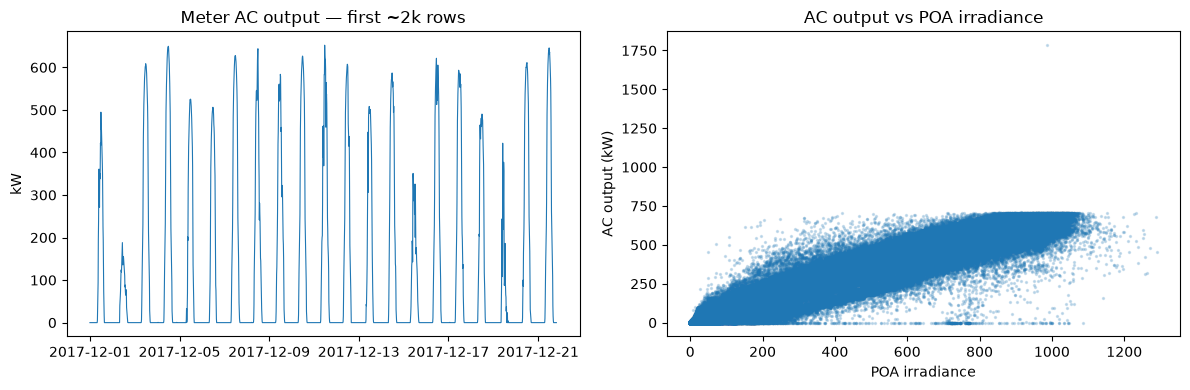

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(baseline_df["measured_on"].head(2000),
             baseline_df[TARGET_COL].head(2000), lw=0.8)
axes[0].set_title("Meter AC output — first ~2k rows"); axes[0].set_ylabel("kW")

axes[1].scatter(baseline_df[IRRADIANCE_COL], baseline_df[TARGET_COL],
                s=2, alpha=0.2)
axes[1].set_title("AC output vs POA irradiance")
axes[1].set_xlabel("POA irradiance"); axes[1].set_ylabel("AC output (kW)")

plt.tight_layout(); plt.show()

**Chronological split — never random.**
Solar is a time series. Random shuffle leaks tomorrow into today → fake-good scores.
Cut: train = everything before 2022-07-01, test = 2022-07-01 → end.
Impute features on TRAIN only, apply to test.

In [11]:
SPLIT_DATE = pd.Timestamp("2022-07-01")

train = baseline_df[baseline_df["measured_on"] <  SPLIT_DATE].copy()
test  = baseline_df[baseline_df["measured_on"] >= SPLIT_DATE].copy()

print(f"train: {len(train):,}  ({train['measured_on'].min().date()} → {train['measured_on'].max().date()})")
print(f"test : {len(test):,}  ({test['measured_on'].min().date()}  → {test['measured_on'].max().date()})")
print(f"train share: {len(train)/len(baseline_df)*100:.1f}%  |  test share: {len(test)/len(baseline_df)*100:.1f}%")

train: 160,396  (2017-12-01 → 2022-06-30)
test : 46,744  (2022-07-01  → 2023-10-31)
train share: 77.4%  |  test share: 22.6%


In [12]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median").fit(train[FEATURES])

train_X = pd.DataFrame(imputer.transform(train[FEATURES]), columns=FEATURES, index=train.index)
test_X  = pd.DataFrame(imputer.transform(test[FEATURES]),  columns=FEATURES, index=test.index)

train_y = train[TARGET_COL].values
test_y  = test[TARGET_COL].values

print("Any NaN left in train_X:", train_X.isna().any().any())
print("Any NaN left in test_X :", test_X.isna().any().any())

Any NaN left in train_X: False
Any NaN left in test_X : False


**v0 = the ruler.** DummyRegressor(strategy="mean") predicts the training mean for every row, no matter the inputs.
Its score is the floor. Any real model must beat it.

In [13]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

v0 = DummyRegressor(strategy="mean").fit(train_X, train_y)
v0_pred = v0.predict(test_X)

def report(name, y_true, y_pred):
    return {
        "model": name,
        "MAE"  : mean_absolute_error(y_true, y_pred),
        "RMSE" : mean_squared_error(y_true, y_pred) ** 0.5,
        "R2"   : r2_score(y_true, y_pred),
    }

results = [report("v0 dummy (mean)", test_y, v0_pred)]
pd.DataFrame(results).round(3)

,model,MAE,RMSE,R2
0,v0 dummy (mean),196.202,231.624,-0.002


**v1 = Linear Regression.** Fits a straight-line relationship: AC ≈ a·POA + b·temp + c·wind + d.
Compare to v0 on the SAME test set. The improvement is the proof that the data has signal.

In [14]:
from sklearn.linear_model import LinearRegression

v1 = LinearRegression().fit(train_X, train_y)
v1_pred = v1.predict(test_X)

results.append(report("v1 linear regression", test_y, v1_pred))

comparison = pd.DataFrame(results).round(3)
comparison["MAE_improvement_vs_v0_%"] = (
    (comparison.loc[0, "MAE"] - comparison["MAE"]) / comparison.loc[0, "MAE"] * 100
).round(1)
comparison

,model,MAE,RMSE,R2,MAE_improvement_vs_v0_%
0,v0 dummy (mean),196.202,231.624,-0.002,0.000
1,v1 linear regression,38.755,66.631,0.917,80.200


In [15]:
coefs = pd.Series(v1.coef_, index=FEATURES).round(3)
print("Intercept:", round(v1.intercept_, 2))
print(coefs)

Intercept: 17.42
poa_irradiance_o_149574         0.642
ambient_temperature_o_149575   -0.282
wind_speed_o_149576             1.807
dtype: float64


## Baseline result

- v0 (dummy mean) MAE = 196 kW  — the floor.
- v1 (linear regression) MAE = 38.8 kW — **80.2% better**. R² = 0.917.
- The 3 features carry strong signal. POA dominates; temperature's coefficient
  direction matches known PV physics (hot panels lose efficiency).
- Test period (Jul 2022 – Oct 2023) includes seasons not fully in train →
  next experiments should check per-month error, not just overall.

## What's next
1. Residual analysis: where does v1 fail? (hot days, mornings, clipping?)
2. Add panel/module temperature + hour-of-day features.
3. Try gradient boosting (LightGBM/XGBoost) — the realistic workhorse.
4. Refactor into `src/solarops/pipeline.py` with functions + tests before adding models.